Days 9–10 — FCI, Entanglement, and DMRG

Objective

The goal was to investigate how the electronic structure of H₂ changes during bond stretching and to compare FCI and DMRG energies.

Main Results

- DMRG reproduced the FCI energies at all four H–H bond distances in the STO-3G basis, with differences at machine precision.
- Entanglement entropy increased from 0.098 to 0.907 bits as the bond distance increased from 1.4 to 4.0 Bohr.
- The magnitude of the FCI–HF correlation energy increased from 0.0206 to 0.1827 Hartree over the same range.

Interpretation

Bond stretching increased both the entanglement entropy and the magnitude of the correlation energy in this dataset. These quantities describe different aspects of electronic correlation and are not equivalent.

Limitations

The calculation used a minimal basis and two active spatial orbitals. Since FCI is inexpensive for this small system, the results validate the DMRG implementation but do not demonstrate a computational advantage over FCI.

Conclusion

This study connects molecular electronic structure with entanglement analysis and tensor-network methods, providing a starting point for future calculations with larger active spaces.

In [ ]:
!pip install pyscf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 12.5 MB/s eta 0:00:00


In [ ]:
from pyscf import gto

mol = gto.M(
    atom='''
    H  0  0  0
    H  0  0  1.4
    ''',
    basis='sto-3g',
    charge=0,
    spin=0,
    unit='Bohr'
)

print("H₂ is ready!")

H₂ is ready!


In [ ]:
from pyscf import scf

mf = scf.RHF(mol)
energy_hf = mf.kernel()

print("HF energy:", energy_hf)

converged SCF energy = -1.11671432506255
HF energy: -1.116714325062551


In [ ]:
from pyscf import fci

cisolver = fci.FCI(mol, mf.mo_coeff)

print("FCI solver is ready!")

FCI solver is ready!


In [ ]:
energy_fci, ci = cisolver.kernel()

print("FCI energy:", energy_fci)

FCI energy: -1.1372759436170439


In [ ]:
print("CI shape:", ci.shape)
print("CI coefficients:")
print(ci)

CI shape: (2, 2)
CI coefficients:
[[ 9.93627297e-01  1.38777878e-16]
 [ 2.47695555e-16 -1.12715549e-01]]


In [ ]:
print("Number of alpha strings:", ci.shape[0])
print("Number of beta strings:", ci.shape[1])

Number of alpha strings: 2
Number of beta strings: 2


In [ ]:
import numpy as np

print("Largest coefficient:", np.max(np.abs(ci)))
print("Smallest non-zero coefficient:", np.min(np.abs(ci[np.abs(ci) > 1e-12])))

Largest coefficient: 0.99362729678065
Smallest non-zero coefficient: 0.11271554947023998


In [ ]:
norm_ci = np.sum(np.abs(ci)**2)

print("CI norm:", norm_ci)

CI norm: 1.0


In [ ]:
probabilities = np.abs(ci)**2

print("Configuration probabilities:")
print(probabilities)

Configuration probabilities:
[[9.87295205e-01 1.92592994e-32]
 [6.13530882e-32 1.27047951e-02]]


In [ ]:
from pyscf import fci

norb = mol.nao_nr()
nelec = mol.nelec

print("Number of spatial orbitals:", norb)
print("Number of alpha electrons:", nelec[0])
print("Number of beta electrons:", nelec[1])

Number of spatial orbitals: 2
Number of alpha electrons: 1
Number of beta electrons: 1


In [ ]:
from pyscf.fci import cistring

alpha_strings = cistring.gen_strings4orblist([0, 1], 1)
beta_strings = cistring.gen_strings4orblist([0, 1], 1)

print("Alpha configurations:", alpha_strings)
print("Beta configurations:", beta_strings)

Alpha configurations: [1 2]
Beta configurations: [1 2]


In [ ]:
print("Alpha strings:", alpha_strings)
print("Beta strings:", beta_strings)

print("\nCI matrix:")
print(ci)

Alpha strings: [1 2]
Beta strings: [1 2]

CI matrix:
[[ 9.93627297e-01  1.38777878e-16]
 [ 2.47695555e-16 -1.12715549e-01]]


In [ ]:
import numpy as np

C_orb = np.zeros((4, 4), dtype=complex)

C_orb[3, 0] = ci[0, 0]
C_orb[0, 3] = ci[1, 1]
C_orb[1, 2] = ci[0, 1]
C_orb[2, 1] = ci[1, 0]

print("Orbital coefficient matrix:")
print(C_orb)

Orbital coefficient matrix:
[[ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
  -1.12715549e-01+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  1.38777878e-16+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j  2.47695555e-16+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 9.93627297e-01+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]]


In [ ]:
U, S, Vh = np.linalg.svd(C_orb)

print("Schmidt coefficients:")
print(S)

Schmidt coefficients:
[9.93627297e-01 1.12715549e-01 2.47695555e-16 1.38777878e-16]


In [ ]:
probabilities = S**2

print("Probabilities:", probabilities)
print("Sum:", probabilities.sum())
print("Norm of CI coefficients:", np.sum(np.abs(ci)**2))
print("Sum of probabilities:", probabilities.sum())

Probabilities: [9.87295205e-01 1.27047951e-02 6.13530882e-32 1.92592994e-32]
Sum: 1.0
Norm of CI coefficients: 1.0
Sum of probabilities: 1.0


In [ ]:
p = probabilities[probabilities > 1e-12]

S_ent = -np.sum(p * np.log2(p))

print("Entanglement entropy:", S_ent)

Entanglement entropy: 0.09823315157001448


In [ ]:
def run_fci(R):
    mol = gto.M(
        atom=f'H 0 0 0; H 0 0 {R}',
        basis='sto-3g',
        unit='Bohr',
        charge=0,
        spin=0
    )

    mf = scf.RHF(mol).run(verbose=0)

    cisolver = fci.FCI(mol, mf.mo_coeff)
    energy_fci, ci = cisolver.kernel()

    return energy_fci, ci

In [ ]:
energy_fci, ci = run_fci(1.4)

print("FCI energy:", energy_fci)
print("CI shape:", ci.shape)

FCI energy: -1.1372759436170439
CI shape: (2, 2)


In [ ]:
energy_fci_22, ci_22 = run_fci(2.2)

print("FCI energy:", energy_fci_22)
print("CI matrix:")
print(ci_22)

FCI energy: -1.064739347320962
CI matrix:
[[ 9.73993010e-01  3.60822483e-16]
 [-8.45074016e-18 -2.26578060e-01]]


In [ ]:
C_orb_22 = np.zeros((4, 4), dtype=complex)

C_orb_22[3, 0] = ci_22[0, 0]
C_orb_22[0, 3] = ci_22[1, 1]
C_orb_22[1, 2] = ci_22[0, 1]
C_orb_22[2, 1] = ci_22[1, 0]

print(C_orb_22)

[[ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
  -2.26578060e-01+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  3.60822483e-16+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j -8.45074016e-18+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 9.73993010e-01+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]]


In [ ]:
U_22, S_22, Vh_22 = np.linalg.svd(C_orb_22)

print("Schmidt coefficients:", S_22)

Schmidt coefficients: [9.73993010e-01 2.26578060e-01 3.60822483e-16 8.45074016e-18]


In [ ]:
probabilities_22 = S_22**2

p_22 = probabilities_22[probabilities_22 > 1e-12]

S_ent_22 = -np.sum(p_22 * np.log2(p_22))

print("Probabilities:", probabilities_22)
print("Sum:", probabilities_22.sum())
print("Entanglement entropy:", S_ent_22)

Probabilities: [9.48662383e-01 5.13376172e-02 1.30192864e-31 7.14150093e-35]
Sum: 0.9999999999999999
Entanglement entropy: 0.2920521127910338


In [ ]:
energy_fci_30, ci_30 = run_fci(3.0)

print("FCI energy:", energy_fci_30)
print("CI matrix:")
print(ci_30)

FCI energy: -0.9851568243679047
CI matrix:
[[ 9.20391599e-01  1.66533454e-16]
 [ 1.42025776e-16 -3.90997832e-01]]


In [ ]:
C_orb_30 = np.zeros((4, 4), dtype=complex)

C_orb_30[3, 0] = ci_30[0, 0]
C_orb_30[0, 3] = ci_30[1, 1]
C_orb_30[1, 2] = ci_30[0, 1]
C_orb_30[2, 1] = ci_30[1, 0]

print(C_orb_30)

[[ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
  -3.90997832e-01+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  1.66533454e-16+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j  1.42025776e-16+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 9.20391599e-01+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]]


In [ ]:
U_30, S_30, Vh_30 = np.linalg.svd(C_orb_30)

print("Schmidt coefficients:", S_30)

Schmidt coefficients: [9.20391599e-01 3.90997832e-01 1.66533454e-16 1.42025776e-16]


In [ ]:
probabilities_30 = S_30**2

p_30 = probabilities_30[probabilities_30 > 1e-12]

S_ent_30 = -np.sum(p_30 * np.log2(p_30))

print("Probabilities:", probabilities_30)
print("Sum:", probabilities_30.sum())
print("Entanglement entropy:", S_ent_30)

Probabilities: [8.47120696e-01 1.52879304e-01 2.77333912e-32 2.01713212e-32]
Sum: 1.0
Entanglement entropy: 0.6169991055846389


In [ ]:
energy_fci_40, ci_40 = run_fci(4.0)

print("FCI energy:", energy_fci_40)
print("CI matrix:")
print(ci_40)

FCI energy: -0.9437784716239701
CI matrix:
[[ 8.23431536e-01  2.22044605e-16]
 [-3.87774432e-16 -5.67415637e-01]]


In [ ]:
import numpy as np
from pyscf import gto, scf, fci

def orbital_entropies(R):
    mol = gto.M(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis="sto-3g",
        unit="Bohr",
        charge=0,
        spin=0,
        verbose=0
    )

    mf = scf.RHF(mol).run(verbose=0)
    solver = fci.FCI(mol, mf.mo_coeff)
    energy, ci = solver.kernel()
    norb = mf.mo_coeff.shape[1]
    nelec = mol.nelec

    dm1, dm2 = solver.make_rdm12(ci, norb, nelec)

    entropies = []

    for i in range(norb):
        n = dm1[i, i].real
        double = dm2[i, i, i, i].real / 2

        probabilities = np.array([
            1 - n + double,       # orbital empty
            n / 2 - double,       # alpha only
            n / 2 - double,       # beta only
            double                # both electrons
        ])

        probabilities[np.abs(probabilities) < 1e-12] = 0

        if np.any(probabilities < 0):
            raise ValueError(
                f"Invalid probabilities at R={R}, orbital={i}: "
                f"{probabilities}"
           )

        probabilities /= probabilities.sum()
        p = probabilities[probabilities > 1e-12]
        entropy = -np.sum(p * np.log2(p))

        entropies.append(entropy)
    return energy, entropies

for R in [1.4, 2.2, 3.0, 4.0]:
    energy, entropies = orbital_entropies(R)
    print(f"R = {R:.1f} Bohr")
    print(f"  FCI energy = {energy:.12f} Eh")
    print(f"  Orbital entropies = {entropies}")

R = 1.4 Bohr
  FCI energy = -1.137275943617 Eh
  Orbital entropies = [np.float64(0.09823315157001439), np.float64(0.09823315157001448)]
R = 2.2 Bohr
  FCI energy = -1.064739347321 Eh
  Orbital entropies = [np.float64(0.2920521127910342), np.float64(0.2920521127910337)]
R = 3.0 Bohr
  FCI energy = -0.985156824368 Eh
  Orbital entropies = [np.float64(0.6169991055846387), np.float64(0.616999105584639)]
R = 4.0 Bohr
  FCI energy = -0.943778471624 Eh
  Orbital entropies = [np.float64(0.906500706330247), np.float64(0.9065007063302468)]


In [ ]:
C_orb_40 = np.zeros((4, 4), dtype=complex)

C_orb_40[3, 0] = ci_40[0, 0]
C_orb_40[0, 3] = ci_40[1, 1]
C_orb_40[1, 2] = ci_40[0, 1]
C_orb_40[2, 1] = ci_40[1, 0]

print(C_orb_40)

[[ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
  -5.67415637e-01+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  2.22044605e-16+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j -3.87774432e-16+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 8.23431536e-01+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]]


In [ ]:
U_40, S_40, Vh_40 = np.linalg.svd(C_orb_40)

print("Schmidt coefficients:", S_40)

Schmidt coefficients: [8.23431536e-01 5.67415637e-01 3.87774432e-16 2.22044605e-16]


In [ ]:
probabilities_40 = S_40**2

p_40 = probabilities_40[probabilities_40 > 1e-12]

S_ent_40 = -np.sum(p_40 * np.log2(p_40))

print("Probabilities:", probabilities_40)
print("Sum:", np.sum(probabilities_40))
print("Entanglement entropy:", S_ent_40)

Probabilities: [6.78039495e-01 3.21960505e-01 1.50369010e-31 4.93038066e-32]
Sum: 0.9999999999999998
Entanglement entropy: 0.906500706330247


In [ ]:
R_values = [1.4, 2.2, 3.0, 4.0]

entropy_values = [
    S_ent,
    S_ent_22,
    S_ent_30,
    S_ent_40
]

for R, entropy in zip(R_values, entropy_values):
    print(f"R = {R:.1f} Bohr | Entropy = {entropy:.6f} bits")


R = 1.4 Bohr | Entropy = 0.098233 bits
R = 2.2 Bohr | Entropy = 0.292052 bits
R = 3.0 Bohr | Entropy = 0.616999 bits
R = 4.0 Bohr | Entropy = 0.906501 bits


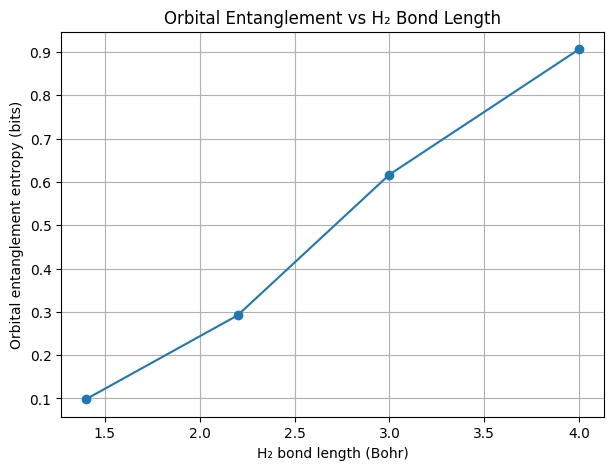

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(R_values, entropy_values, marker="o")

plt.xlabel("H₂ bond length (Bohr)")
plt.ylabel("Orbital entanglement entropy (bits)")
plt.title("Orbital Entanglement vs H₂ Bond Length")

plt.grid(True)
plt.show()

In [ ]:
def run_hf(R):
      mol = gto.M(
              atom=f'H 0 0 0; H 0 0 {R}',
              basis='sto-3g',
              unit='Bohr',
              charge=0,
              spin=0
      )

      mf = scf.RHF(mol).run(verbose=0)
      return mf.e_tot


R_values = [1.4, 2.2, 3.0, 4.0]

HF_energies = [run_hf(R) for R in R_values]

for R, E in zip(R_values, HF_energies):
                                                                  print(f"R = {R:.1f} Bohr | HF energy = {E:.12f} Eh")

R = 1.4 Bohr | HF energy = -1.116714325063 Eh
R = 2.2 Bohr | HF energy = -1.016485721517 Eh
R = 3.0 Bohr | HF energy = -0.885275000111 Eh
R = 4.0 Bohr | HF energy = -0.761082247024 Eh


In [ ]:
FCI_energies = [
      -1.1372759436170439,
      -1.064739347320962,
      -0.9851568243679047,
      -0.9437784716239701
]

correlation_energies = [
      E_fci - E_hf
      for E_fci, E_hf in zip(FCI_energies, HF_energies)
]

for R, E_corr in zip(R_values, correlation_energies):
    print(f"R = {R:.1f} Bohr | E_corr = {E_corr:.12f} Eh")


R = 1.4 Bohr | E_corr = -0.020561618554 Eh
R = 2.2 Bohr | E_corr = -0.048253625804 Eh
R = 3.0 Bohr | E_corr = -0.099881824257 Eh
R = 4.0 Bohr | E_corr = -0.182696224600 Eh


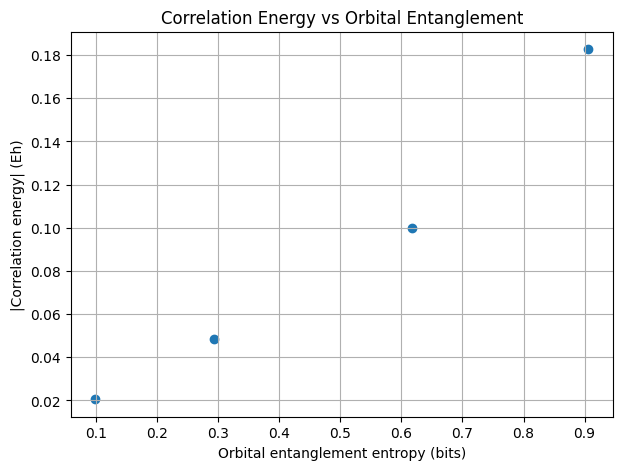

In [ ]:
correlation_strength = np.abs(correlation_energies)

plt.figure(figsize=(7, 5))
plt.scatter(entropy_values, correlation_strength)

plt.xlabel("Orbital entanglement entropy (bits)")
plt.ylabel("|Correlation energy| (Eh)")
plt.title("Correlation Energy vs Orbital Entanglement")
plt.grid(True)

plt.show()

In [ ]:
!pip install block2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.8/124.8 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.5/195.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.8 MB/s eta 0:00:00
  Attempting uninstall: tbb
    Found existing installation: tbb 2022.3.1
    Uninstalling tbb-2022.3.1:
      Successfully uninstalled tbb-2022.3.1
  Attempting uninstall: onemkl-license
    Found existing installation: onemkl-license 2025.3.1
    Uninstalling onemkl-license-2025.3.1:
      Successfully uninstalled onemkl-license-2025.3.1
  Attempting uninstall: mkl
    Found existing installation: mkl 2025.3.1
    Uninstalling mkl-2025.3.1:
      Successfully uninstalled mkl-2025.3.1


In [ ]:
import block2
print("Block2 imported successfully")

Block2 imported successfully


In [ ]:
from pyblock2._pyscf.ao2mo import integrals as itg
from pyscf import gto, scf

R = 1.4

mol = gto.M(
    atom=f'H 0 0 0; H 0 0 {R}',
    basis='sto-3g',
    unit='Bohr',
    symmetry='d2h',
    charge=0,
    spin=0,
    verbose=0
)

mf = scf.RHF(mol).run(conv_tol=1e-14)

ncas, n_elec, spin, ecore, h1_dmrg, g2_dmrg, orb_sym = (
    itg.get_rhf_integrals(
        mf,
        ncore=0,
       ncas=None,
       g2e_symm=8
    )
)

print("Number of orbitals:", ncas)
print("Number of electrons:", n_elec)
print("Spin:", spin)
print("One-electron integrals shape:", h1_dmrg.shape)
print("Two-electron integrals shape:", g2_dmrg.shape)
print("Orbital symmetries:", orb_sym)

Number of orbitals: 2
Number of electrons: 2
Spin: 0
One-electron integrals shape: (2, 2)
Two-electron integrals shape: (6,)
Orbital symmetries: [0, 5]


In [ ]:
from pyblock2.driver.core import DMRGDriver, SymmetryTypes

driver = DMRGDriver(
    symm_type=SymmetryTypes.SU2,
    n_threads=1
)

driver.initialize_system(
    n_sites=ncas,
    n_elec=n_elec,
    spin=spin,
    orb_sym=orb_sym
)

print("Block2 initialized with orbital symmetries")

Block2 initialized with orbital symmetries


In [ ]:
mpo = driver.get_qc_mpo(
    h1e=h1_dmrg,
    g2e=g2_dmrg,
    ecore=ecore
)

print("Corrected Hamiltonian MPO created")

integral symmetrize error =  8.200552170708153e-16
integral cutoff error =  0.0
mpo terms =         12

Build MPO | Nsites =     2 | Nterms =         12 | Algorithm = FastBIP | Cutoff = 1.00e-20
 Site =     0 /     2 .. Mmpo =     8 DW = 0.00e+00 NNZ =        8 SPT = 0.0000 Tmvc = 0.000 T = 0.007
 Site =     1 /     2 .. Mmpo =     1 DW = 0.00e+00 NNZ =        8 SPT = 0.0000 Tmvc = 0.000 T = 0.002
Ttotal =      0.009 Tmvc-total = 0.000 MPO bond dimension =     8 MaxDW = 0.00e+00
NNZ =           16 SIZE =           16 SPT = 0.0000

Rank =     0 Ttotal =      0.016 MPO method = FastBipartite bond dimension =       8 NNZ =           16 SIZE =           16 SPT = 0.0000
Corrected Hamiltonian MPO created


In [ ]:
ket = driver.get_random_mps(
    tag="H2_corrected",
    bond_dim=10,
    center=0,
    dot=2
)

print("Corrected MPS created")

Corrected MPS created


In [ ]:
energy_dmrg_corrected = driver.dmrg(
      mpo,
      ket,
      n_sweeps=4,
      bond_dims=[10, 10, 10, 10],
      noises=[1e-5, 1e-6, 0.0, 0.0],
      thrds=[1e-6, 1e-8, 1e-10, 1e-10],
      iprint=1
)

print("Corrected DMRG energy:", energy_dmrg_corrected)
print("Bond distance R:", R, "Bohr")
print("Hartree-Fock energy:", mf.e_tot)
print("DMRG energy:", energy_dmrg_corrected)


Sweep =    0 | Direction =  forward | Bond dimension =   10 | Noise =  1.00e-05 | Dav threshold =  1.00e-06
Time elapsed =      0.013 | E =      -1.1372759436 | DW = 0.00000e+00

Sweep =    1 | Direction = backward | Bond dimension =   10 | Noise =  1.00e-06 | Dav threshold =  1.00e-08
Time elapsed =      0.035 | E =      -1.1372759436 | DE = -4.44e-16 | DW = 0.00000e+00

Sweep =    2 | Direction =  forward | Bond dimension =   10 | Noise =  0.00e+00 | Dav threshold =  1.00e-10
Time elapsed =      0.053 | E =      -1.1372759436 | DE = 0.00e+00 | DW = 0.00000e+00

Corrected DMRG energy: -1.1372759436170439
Bond distance R: 1.4 Bohr
Hartree-Fock energy: -1.116714325062552
DMRG energy: -1.1372759436170439


In [ ]:
from pyscf import gto, scf

R = 2.2

mol = gto.M(
    atom=f'H 0 0 0; H 0 0 {R}',
    basis='sto-3g',
    unit='Bohr',
    charge=0,
    spin=0,
    verbose=0
)

mf = scf.RHF(mol).run(conv_tol=1e-14)

print("Bond distance:", R, "Bohr")
print("Hartree-Fock energy:", mf.e_tot)

Bond distance: 2.2 Bohr
Hartree-Fock energy: -1.0164857215170233


In [ ]:
from pyblock2._pyscf.ao2mo import integrals as itg

ncas, n_elec, spin, ecore, h1_dmrg, g2_dmrg, orb_sym = (
    itg.get_rhf_integrals(
        mf,
        ncore=0,
        ncas=None,
        g2e_symm=8
    )
)

print("Active orbitals:", ncas)
print("Electrons:", n_elec)
print("Spin:", spin)
print("Core energy:", ecore)
print("One-electron integrals shape:", h1_dmrg.shape)
print("Two-electron integrals shape:", g2_dmrg.shape)
print("Orbital symmetries:", orb_sym)

Active orbitals: 2
Electrons: 2
Spin: 0
Core energy: 0.45454545454545453
One-electron integrals shape: (2, 2)
Two-electron integrals shape: (6,)
Orbital symmetries: [0, 0]


In [ ]:
driver = DMRGDriver(
      symm_type=SymmetryTypes.SU2,
      n_threads=1
)

driver.initialize_system(
      n_sites=ncas,
      n_elec=n_elec,
      spin=spin,
      orb_sym=orb_sym
)

mpo = driver.get_qc_mpo(
      h1e=h1_dmrg,
      g2e=g2_dmrg,
      ecore=ecore
)

ket = driver.get_random_mps(
      tag="H2_R2.2",
      bond_dim=10,
      center=0,
      dot=2
)

energy_dmrg_R22 = driver.dmrg(
      mpo,
      ket,
      n_sweeps=4,
      bond_dims=[10, 10, 10, 10],
      noises=[1e-5, 1e-6, 0.0, 0.0],
      thrds=[1e-6, 1e-8, 1e-10, 1e-10],
      iprint=1
)

print("DMRG energy at R=2.2 Bohr:", energy_dmrg_R22)

integral symmetrize error =  0.0
integral cutoff error =  0.0
mpo terms =         21

Build MPO | Nsites =     2 | Nterms =         21 | Algorithm = FastBIP | Cutoff = 1.00e-20
 Site =     0 /     2 .. Mmpo =    12 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.002
 Site =     1 /     2 .. Mmpo =     1 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.002
Ttotal =      0.003 Tmvc-total = 0.000 MPO bond dimension =    12 MaxDW = 0.00e+00
NNZ =           24 SIZE =           24 SPT = 0.0000

Rank =     0 Ttotal =      0.011 MPO method = FastBipartite bond dimension =      12 NNZ =           24 SIZE =           24 SPT = 0.0000

Sweep =    0 | Direction =  forward | Bond dimension =   10 | Noise =  1.00e-05 | Dav threshold =  1.00e-06
Time elapsed =      0.005 | E =      -1.0647393473 | DW = 0.00000e+00

Sweep =    1 | Direction = backward | Bond dimension =   10 | Noise =  1.00e-06 | Dav threshold =  1.00e-08
Time elapsed =      0.009 | E =      -1.0647393473 | DE 

In [ ]:
from pyscf import gto, scf

R = 3.0

mol = gto.M(
    atom=f'H 0 0 0; H 0 0 {R}',
    basis='sto-3g',
    unit='Bohr',
    charge=0,
    spin=0,
    verbose=0
)

mf = scf.RHF(mol).run(conv_tol=1e-14)

print("Bond distance:", R, "Bohr")
print("Hartree-Fock energy:", mf.e_tot)

Bond distance: 3.0 Bohr
Hartree-Fock energy: -0.8852750001110465


In [ ]:
from pyblock2._pyscf.ao2mo import integrals as itg

ncas, n_elec, spin, ecore, h1_dmrg, g2_dmrg, orb_sym = (
    itg.get_rhf_integrals(
        mf,
        ncore=0,
        ncas=None,
        g2e_symm=8
    )
)

print("Active orbitals:", ncas)
print("Electrons:", n_elec)
print("Spin:", spin)
print("Core energy:", ecore)
print("One-electron integrals shape:", h1_dmrg.shape)
print("Two-electron integrals shape:", g2_dmrg.shape)
print("Orbital symmetries:", orb_sym)

Active orbitals: 2
Electrons: 2
Spin: 0
Core energy: 0.3333333333333333
One-electron integrals shape: (2, 2)
Two-electron integrals shape: (6,)
Orbital symmetries: [0, 0]


In [ ]:
driver = DMRGDriver(
      symm_type=SymmetryTypes.SU2,
      n_threads=1
)

driver.initialize_system(
      n_sites=ncas,
      n_elec=n_elec,
      spin=spin,
      orb_sym=orb_sym
)

mpo = driver.get_qc_mpo(
      h1e=h1_dmrg,
      g2e=g2_dmrg,
      ecore=ecore
)

ket = driver.get_random_mps(
      tag="H2_R3.0",
      bond_dim=10,
      center=0,
      dot=2
)

energy_dmrg_R30 = driver.dmrg(
      mpo,
      ket,
      n_sweeps=4,
      bond_dims=[10, 10, 10, 10],
      noises=[1e-5, 1e-6, 0.0, 0.0],
      thrds=[1e-6, 1e-8, 1e-10, 1e-10],
      iprint=1
)

print("DMRG energy at R=3.0 Bohr:", energy_dmrg_R30)

integral symmetrize error =  0.0
integral cutoff error =  0.0
mpo terms =         21

Build MPO | Nsites =     2 | Nterms =         21 | Algorithm = FastBIP | Cutoff = 1.00e-20
 Site =     0 /     2 .. Mmpo =    12 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.002
 Site =     1 /     2 .. Mmpo =     1 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.002
Ttotal =      0.004 Tmvc-total = 0.000 MPO bond dimension =    12 MaxDW = 0.00e+00
NNZ =           24 SIZE =           24 SPT = 0.0000

Rank =     0 Ttotal =      0.011 MPO method = FastBipartite bond dimension =      12 NNZ =           24 SIZE =           24 SPT = 0.0000

Sweep =    0 | Direction =  forward | Bond dimension =   10 | Noise =  1.00e-05 | Dav threshold =  1.00e-06
Time elapsed =      0.003 | E =      -0.9851568244 | DW = 0.00000e+00

Sweep =    1 | Direction = backward | Bond dimension =   10 | Noise =  1.00e-06 | Dav threshold =  1.00e-08
Time elapsed =      0.007 | E =      -0.9851568244 | DE 

In [ ]:
from pyscf import gto, scf

R = 4.0

mol = gto.M(
    atom=f'H 0 0 0; H 0 0 {R}',
    basis='sto-3g',
    unit='Bohr',
    charge=0,
    spin=0,
    verbose=0
)

mf = scf.RHF(mol).run(conv_tol=1e-14)

print("Bond distance:", R, "Bohr")
print("Hartree-Fock energy:", mf.e_tot)

Bond distance: 4.0 Bohr
Hartree-Fock energy: -0.7610822470242358


In [ ]:
from pyblock2._pyscf.ao2mo import integrals as itg

ncas, n_elec, spin, ecore, h1_dmrg, g2_dmrg, orb_sym = (
    itg.get_rhf_integrals(
        mf,
        ncore=0,
        ncas=None,
        g2e_symm=8
    )
)

print("Active orbitals:", ncas)
print("Electrons:", n_elec)
print("Spin:", spin)
print("Core energy:", ecore)
print("One-electron integrals shape:", h1_dmrg.shape)
print("Two-electron integrals shape:", g2_dmrg.shape)
print("Orbital symmetries:", orb_sym)

Active orbitals: 2
Electrons: 2
Spin: 0
Core energy: 0.25
One-electron integrals shape: (2, 2)
Two-electron integrals shape: (6,)
Orbital symmetries: [0, 0]


In [ ]:
driver = DMRGDriver(
      symm_type=SymmetryTypes.SU2,
      n_threads=1
)

driver.initialize_system(
      n_sites=ncas,
      n_elec=n_elec,
      spin=spin,
      orb_sym=orb_sym
)

mpo = driver.get_qc_mpo(
      h1e=h1_dmrg,
      g2e=g2_dmrg,
      ecore=ecore
)

ket = driver.get_random_mps(
      tag="H2_R4.0",
      bond_dim=10,
      center=0,
      dot=2
)

energy_dmrg_R40 = driver.dmrg(
      mpo,
      ket,
      n_sweeps=4,
      bond_dims=[10, 10, 10, 10],
      noises=[1e-5, 1e-6, 0.0, 0.0],
      thrds=[1e-6, 1e-8, 1e-10, 1e-10],
      iprint=1
)

print("DMRG energy at R=4.0 Bohr:", energy_dmrg_R40)

integral symmetrize error =  0.0
integral cutoff error =  0.0
mpo terms =         21

Build MPO | Nsites =     2 | Nterms =         21 | Algorithm = FastBIP | Cutoff = 1.00e-20
 Site =     0 /     2 .. Mmpo =    12 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.004
 Site =     1 /     2 .. Mmpo =     1 DW = 0.00e+00 NNZ =       12 SPT = 0.0000 Tmvc = 0.000 T = 0.004
Ttotal =      0.008 Tmvc-total = 0.000 MPO bond dimension =    12 MaxDW = 0.00e+00
NNZ =           24 SIZE =           24 SPT = 0.0000

Rank =     0 Ttotal =      0.016 MPO method = FastBipartite bond dimension =      12 NNZ =           24 SIZE =           24 SPT = 0.0000

Sweep =    0 | Direction =  forward | Bond dimension =   10 | Noise =  1.00e-05 | Dav threshold =  1.00e-06
Time elapsed =      0.003 | E =      -0.9437784716 | DW = 0.00000e+00

Sweep =    1 | Direction = backward | Bond dimension =   10 | Noise =  1.00e-06 | Dav threshold =  1.00e-08
Time elapsed =      0.006 | E =      -0.9437784716 | DE 

In [ ]:
import json

saved_results = {
    "bond_distances_bohr": [1.4, 2.2, 3.0, 4.0],
    "HF_energies_Eh": [
        -1.116714325063,
        -1.016485721517,
        -0.885275000111,
        -0.761082247024
    ],
    "FCI_energies_Eh": [
        -1.1372759436170439,
        -1.064739347320962,
        -0.9851568243679047,
        -0.9437784716239701
    ],
    "DMRG_energies_Eh": [
         float(energy_dmrg_corrected),
         float(energy_dmrg_R22),
         float(energy_dmrg_R30),
         float(energy_dmrg_R40)
    ],
    "entanglement_entropy_bits": [
         0.09823315157,
         0.29205211279,
         0.616999105585,
         0.90650070633
    ]
}

with open("/content/day9_results.json", "w") as f:
    json.dump(saved_results, f, indent= 2)
    print("Results saved successfully.")

Results saved successfully.


In [ ]:
import pandas as pd

results = pd.DataFrame({
"R (Bohr)": saved_results["bond_distances_bohr"],
"HF (Eh)": saved_results["HF_energies_Eh"],
"FCI (Eh)": saved_results["FCI_energies_Eh"],
"DMRG (Eh)": saved_results["DMRG_energies_Eh"],
"Entropy (bits)": saved_results["entanglement_entropy_bits"]
})

results["|DMRG-FCI|"] = abs(results["DMRG (Eh)"] - results["FCI (Eh)"])
results["Correlation energy (Eh)"] = results["FCI (Eh)"] - results["HF (Eh)"]

display(results.round(10))

,R (Bohr),HF (Eh),FCI (Eh),DMRG (Eh),Entropy (bits),|DMRG-FCI|,Correlation energy (Eh)
0,1.4,-1.116714,-1.137276,-1.137276,0.098233,0.0,-0.020562
1,2.2,-1.016486,-1.064739,-1.064739,0.292052,0.0,-0.048254
2,3.0,-0.885275,-0.985157,-0.985157,0.616999,0.0,-0.099882
3,4.0,-0.761082,-0.943778,-0.943778,0.906501,0.0,-0.182696


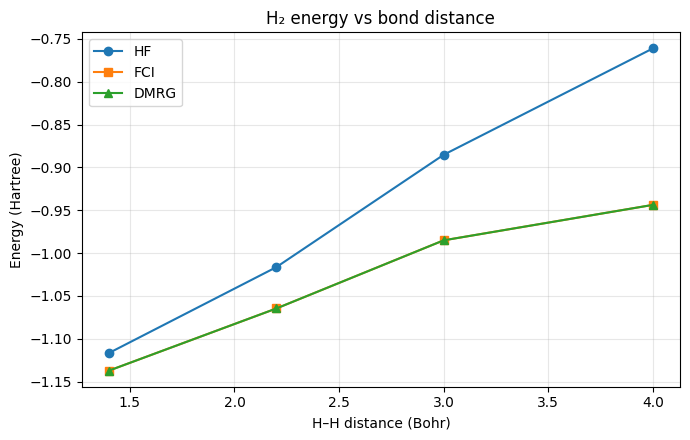

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4.5))
plt.plot(results["R (Bohr)"], results["HF (Eh)"], "o-", label="HF")
plt.plot(results["R (Bohr)"], results["FCI (Eh)"], "s-", label="FCI")
plt.plot(results["R (Bohr)"], results["DMRG (Eh)"], "^-", label="DMRG")

plt.xlabel("H–H distance (Bohr)")
plt.ylabel("Energy (Hartree)")
plt.title("H₂ energy vs bond distance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

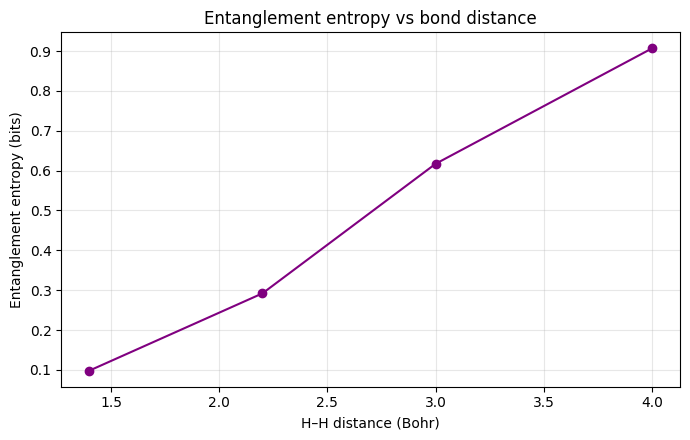

In [ ]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    results["R (Bohr)"],
    results["Entropy (bits)"],
    "o-",
    color="purple"
)

plt.xlabel("H–H distance (Bohr)")
plt.ylabel("Entanglement entropy (bits)")
plt.title("Entanglement entropy vs bond distance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

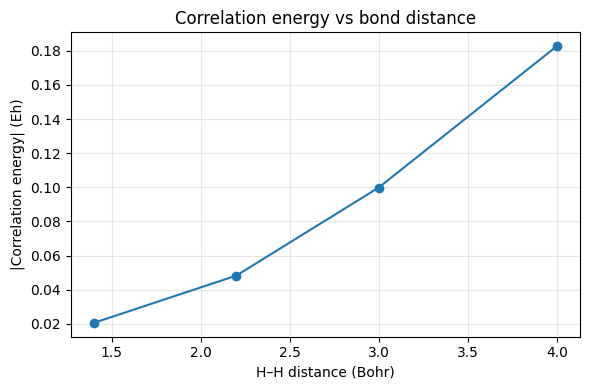

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(
    results["R (Bohr)"],
    abs(results["Correlation energy (Eh)"]),
    "o-"
)
plt.xlabel("H–H distance (Bohr)")
plt.ylabel("|Correlation energy| (Eh)")
plt.title("Correlation energy vs bond distance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("FCI energies:")
print(FCI_energies)

print("\nDMRG energies:")
print([
    energy_dmrg_corrected,
    energy_dmrg_R22,
    energy_dmrg_R30,
    energy_dmrg_R40
])

print("\nAbsolute differences:")
for R, E_fci, E_dmrg in zip(
    [1.4, 2.2, 3.0, 4.0],
    FCI_energies,
    [
        energy_dmrg_corrected,
        energy_dmrg_R22,
        energy_dmrg_R30,
        energy_dmrg_R40
    ]
):
    print(f"R = {R:.1f} Bohr: |DMRG - FCI| = {abs(E_dmrg - E_fci):.12e} Eh")

FCI energies:
[-1.1372759436170439, -1.064739347320962, -0.9851568243679047, -0.9437784716239701]

DMRG energies:
[-1.1372759436170439, -1.0647393473209623, -0.985156824367905, -0.9437784716239708]

Absolute differences:
R = 1.4 Bohr: |DMRG - FCI| = 0.000000000000e+00 Eh
R = 2.2 Bohr: |DMRG - FCI| = 2.220446049250e-16 Eh
R = 3.0 Bohr: |DMRG - FCI| = 2.220446049250e-16 Eh
R = 4.0 Bohr: |DMRG - FCI| = 6.661338147751e-16 Eh


In [ ]:
def entropy_from_ci(ci):
      p = np.abs(ci.ravel())**2
      p = p[p > 1e-12]
      return -np.sum(p * np.log2(p))

ci_data = [
      (1.4, ci, S_ent),
      (2.2, ci_22, S_ent_22),
      (3.0, ci_30, S_ent_30),
      (4.0, ci_40, S_ent_40)
]

for R, ci_R, entropy_svd in ci_data:
    entropy_direct = entropy_from_ci(ci_R)

    print(f"R = {R:.1f} Bohr")
    print(f"  Entropy from SVD:    {entropy_svd:.10f}")
    print(f"  Entropy from CI:     {entropy_direct:.10f}")
    print(f"  Absolute difference: {abs(entropy_svd - entropy_direct):.3e}")

In [ ]:

R_values = [1.4, 2.2, 3.0, 4.0]

orbital_entropy_results = []

for R in R_values:
    energy, entropies = orbital_entropies(R)

    orbital_entropy_results.append({
        "R (Bohr)": R,
        "FCI energy (Eh)": energy,
        "Orbital 1 entropy (bits)": entropies[0],
        "Orbital 2 entropy (bits)": entropies[1]
    })

import pandas as pd

entropy_df = pd.DataFrame(orbital_entropy_results)
display(entropy_df.round(8))


,R (Bohr),FCI energy (Eh),Orbital 1 entropy (bits),Orbital 2 entropy (bits)
0,1.4,-1.137276,0.098233,0.098233
1,2.2,-1.064739,0.292052,0.292052
2,3.0,-0.985157,0.616999,0.616999
3,4.0,-0.943778,0.906501,0.906501
